In [1]:
# import os
# os.getcwd()

In [2]:
# Add directory to my path
import sys
sys.path.append('C:\\Users\\melch\\OneDrive\\Documents\\Fraud-Detection-ACH\\functions')

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from data_quality import check_duplicates
from dow_features import create_dow_features
from windowed import windowed_count, windowed_fraud_count
from preprocessing import train_val_split
from visualization_plots import barchart_fraud_rate, woe_plot_encode, histogram_fraud

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

holidays is already installed.


## 1) Basic Exploration and Data Quality Check

##### This section performs initial steps that should take place BEFORE splitting into training/testing data

-  The data had 0.498% duplicate rows which were removed
-  Some data types were converted
-  2023-01-01 payments were removed in case they were unintentionally included
-  4 fields have missing values. 3 will be imputed after the split to avoid data leakage, but "transactionType" had its missings treated as their own category
-  "senderID" and "receiverID" have large cardinality, so rather than encode them, they were used to create lookback window counts
-  The fraud rate is just over 9%, so there is a class imbalance similar to what would be seen in real-world fraud detection problems.
-  Data was split 75/25 train/test

In [4]:
# Remove duplicates
df = pd.read_csv("../data/ach_transactions.csv")
df = check_duplicates(df, True)

Out of 5,025 rows, the dataset has 25 duplicates for a duplicate rate of:
0.498%

Duplicate rows have been dropped. There are 5,000 remaining.


In [5]:
# Quickly visualize the data and check data types
print(df.info(), df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   senderID             5000 non-null   int64  
 1   amount               5000 non-null   float64
 2   transactionDate      5000 non-null   int64  
 3   hasMemo              5000 non-null   int64  
 4   receiverID           5000 non-null   int64  
 5   senderAcctTenure     4989 non-null   float64
 6   receiverAcctTenure   4986 non-null   float64
 7   transactionType      4504 non-null   object 
 8   transactionDistance  4975 non-null   float64
 9   fraud                5000 non-null   int64  
dtypes: float64(4), int64(5), object(1)
memory usage: 390.8+ KB
None    senderID  amount  transactionDate  hasMemo  receiverID  senderAcctTenure  \
0     26283   44.68         20220427        0       90719             652.0   
1     83012   34.77         20220917        0       90612         

In [6]:
'''
There are missing values for 4 of the fields. Some of data types don't match what the field is representing. I can quickly convert
transactionDate and the two ID fields to their appropriate type. The tenure fields have to be imputed in some way, but that can 
only happen after the train/test split to avoid data leakage.
'''
df["senderID"] = df["senderID"].astype(str)
df["receiverID"] = df["receiverID"].astype(str)
df['transactionDate'] = pd.to_datetime(df['transactionDate'], format = '%Y%m%d')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   senderID             5000 non-null   object        
 1   amount               5000 non-null   float64       
 2   transactionDate      5000 non-null   datetime64[ns]
 3   hasMemo              5000 non-null   int64         
 4   receiverID           5000 non-null   object        
 5   senderAcctTenure     4989 non-null   float64       
 6   receiverAcctTenure   4986 non-null   float64       
 7   transactionType      4504 non-null   object        
 8   transactionDistance  4975 non-null   float64       
 9   fraud                5000 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(2), object(3)
memory usage: 390.8+ KB


In [7]:
# Look at the non-numeric data to get an overview of how many unique values they have
print(df.select_dtypes(exclude = 'number').apply((pd.Series.nunique)))

senderID           489
transactionDate    366
receiverID         246
transactionType      3
dtype: int64


In [8]:
'''
Both ID fields have too many unique values to efficiently be encoded, so I will deal with them in a different way. "transactionType" has only 3
unique values, so I can handle the missing values by creating them as their own category and then later encoding. I'll quickly look at
the range of "transactionDate".
'''
print(f"\nThe minimimum date is {df['transactionDate'].min()} and the maximum is {df['transactionDate'].max()}")
# There is 1 year of transaction data, but appears to have some extra payments on 2023-01-01. I'll investigate further.
extra_rows = df[df["transactionDate"].dt.to_period("Y") == "2023"]
print(f"\nThe 2023 payments have {extra_rows.shape[0]} rows and {extra_rows['fraud'].sum()} frauds")


The minimimum date is 2022-01-01 00:00:00 and the maximum is 2023-01-01 00:00:00

The 2023 payments have 13 rows and 0 frauds


In [9]:
'''
The 2023-01-01 payments have no fraud and only 13 payments. This can be concerning, because fraud can trail off towards the recent end of a dataset
as the fraudulent payments haven't been reported yet. Alternatively, this could be a data quality issue if the data was only intended to be for
2022. To be safe, I'll remove the 2023-01-01 transactions and proceed with just 2022.
'''
df = df[df["transactionDate"].dt.to_period("Y") == "2022"].reset_index(drop = True)

In [10]:
'''
The ID fields have too many distinct categories to be brought into the data with traditional encoding methods. Instead, since they are IDs,
an option is to create a lookback window and count the number of times that sender/receiver has been seen previously, and how many frauds have
been associated with them. This needs to be done prior to splitting because the entire dataset needs to be used when looking back.

This data isn't set up perfectly to do this, at there is no timestamp so same day payments cannot be ordered, so I decided not to count same day payments. 
Also, payments with earlier transaction dates don't have long lookback windows available, so the model might perform better away from the earlier month(s).
'''
df = windowed_count(df, "transactionDate", "senderID", "left", "count", ["2d", "7d", "30d", "90d"])
df = windowed_count(df, "transactionDate", "receiverID", "left", "count", ["2d", "7d", "30d", "90d"])
df = windowed_fraud_count(df, "transactionDate", "senderID", "left", "count", "fraud", ["2d", "7d", "30d", "90d"])
df = windowed_fraud_count(df, "transactionDate", "receiverID", "left", "count", "fraud", ["2d", "7d", "30d", "90d"])

In [11]:
# Check summary statistics
round(100 * df["fraud"].mean(), 3)
# The fraud rate is ~ 9%. That makes the fraud target imbalanced.

np.float64(9.244)

In [12]:
# For now, treat the missing values for transactionType as their own group due to low cardinality
df["transactionType"] = df["transactionType"].fillna("Missing")

In [13]:
# Split the data
df_train, df_val = train_val_split(df, 0.75, 1234, "fraud")

The training data's fraud rate is 9.251% and the validation data's fraud rate is 9.222%


## 2) Visualizations

##### This section uses visualizations to derive insights

-  In the interest of both time and conciseness, I showed examples of useful visualizations instead of all possiblities.
-  Line Chart: Payment volume has the typical peaks and valleys associated with payments over the calendar year. If the peaks coincide with holidays, a holiday indicator would help the model. Neither the train nor test data has any bias towards a particular time period.
-  Bar Charts / WoE Plots: Looking at month as a possible categorical feature, there is a degree of similarity in the fraud rate spikes and dips, particularly in February and May. On the other hand, "transactionType" is far more consistent bewteen train and test. The two high fraud groups are "Gift" and "Missing", which justifies using the missings as their own group. The weight of evidence plots factor in payment volume in addition to fraud rate, and February/May have the largest WoE values indicating they are most associated with fraud/nonfraud respectively. For "transactionType", the WoE values reflect what we would expect based on the barchart.
-  Encoding: I will use WoE to encode "Month" and "transactionType" as these are the two categorical features I plan on using.
-  Histograms: One conclusion that can be drawn immediately is that most of the payments are for smaller dollar amounts and for smaller distances between the two parties. The count of fraudulent transactions is higher amongst smaller values for amount and distance, so it can be inferred that fraud is inversely proportional to both transaction amount and transaction distance.
- Outliers: The histograms indicated there are extreme values for both transaction amount and transaction distance. I know up front I will be trying a boosting method during model training, and boosting is robust enough to handle outliers. I also don't know that these data points are actually illegitimate, and not an accurate variant in the data. With that in mind, I will keep them in the data.

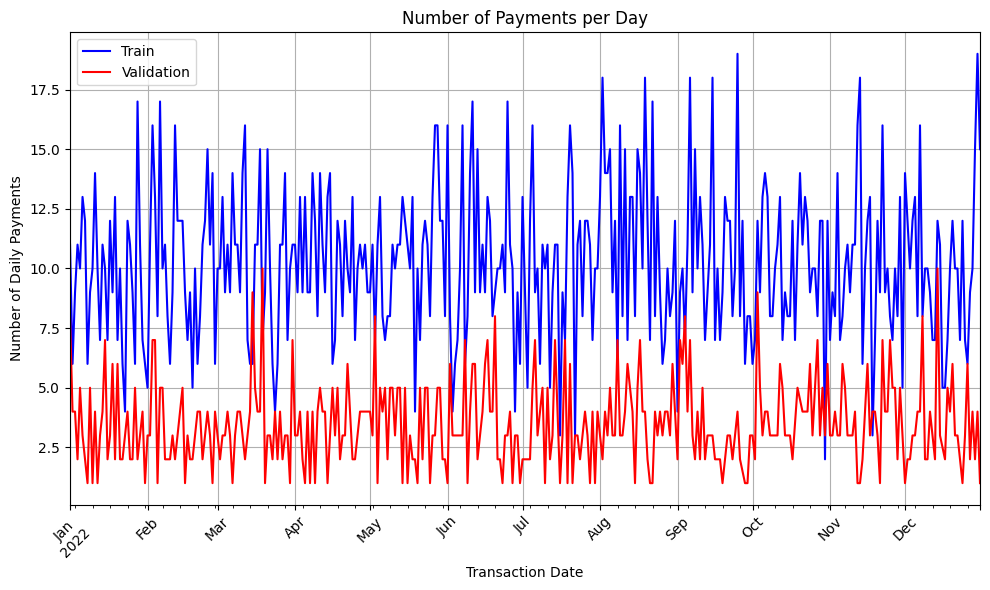

In [14]:
# Start with looking at daily payment volume

# Get the daily payment counts
train_cnts = df_train.groupby("transactionDate").size()
val_cnts = df_val.groupby("transactionDate").size()

# Plot the line charts
plt.figure(figsize = (10, 6))
train_cnts.plot(kind = "line", color = "blue", label = "Train")
val_cnts.plot(kind = "line", color = "red", label = "Validation")
plt.xlabel("Transaction Date")
plt.ylabel("Number of Daily Payments")
plt.title("Number of Payments per Day")
plt.legend()
plt.grid(True)
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

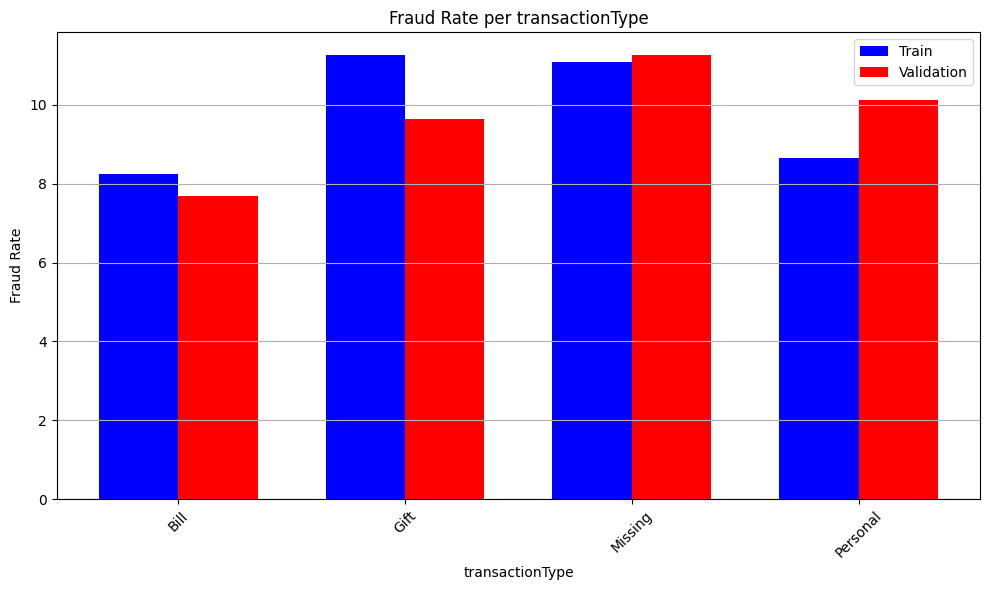

In [15]:
barchart_fraud_rate(df_train, df_val, "Train", "Validation", "transactionType", "fraud")

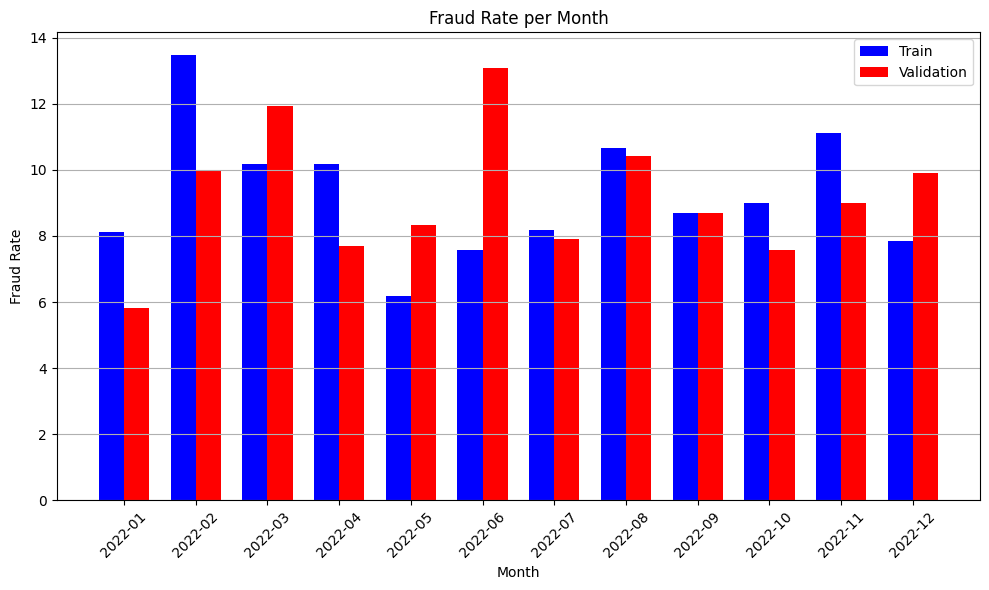

In [16]:
# Extract the month from date
df_train["Month"] = df_train["transactionDate"].dt.to_period("M")
df_val["Month"] = df_val["transactionDate"].dt.to_period("M")
# Plot the bar chart to show fraud rate per month 
barchart_fraud_rate(df_train, df_val, "Train", "Validation", "Month", "fraud")

The feature "transactionType" has been encoded using weight of evidence


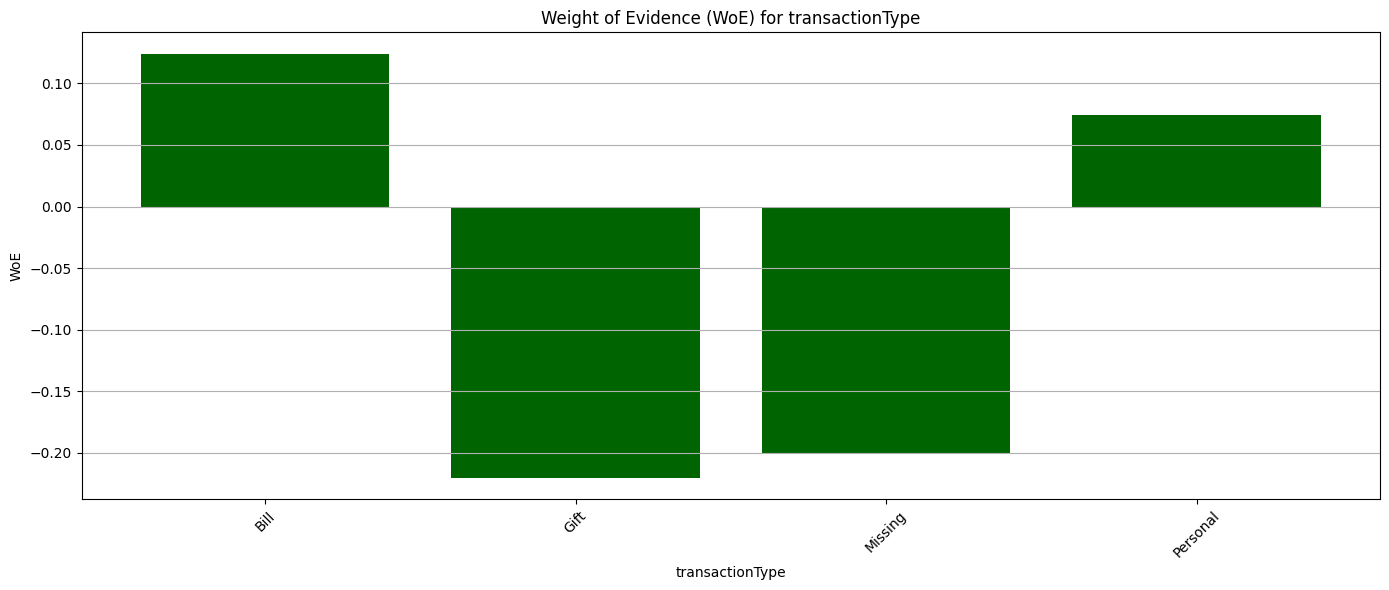

In [17]:
'''
The bar chart shows each category's fraud rate, but does not factor in volume of payments. A weight of evidence plot does that, so I will
proceed with a WoE plot AND encode the categorical features at the same time.
'''

df_train, df_val = woe_plot_encode(df_train, "transactionType", "fraud", "darkgreen", df_val)

The feature "Month" has been encoded using weight of evidence


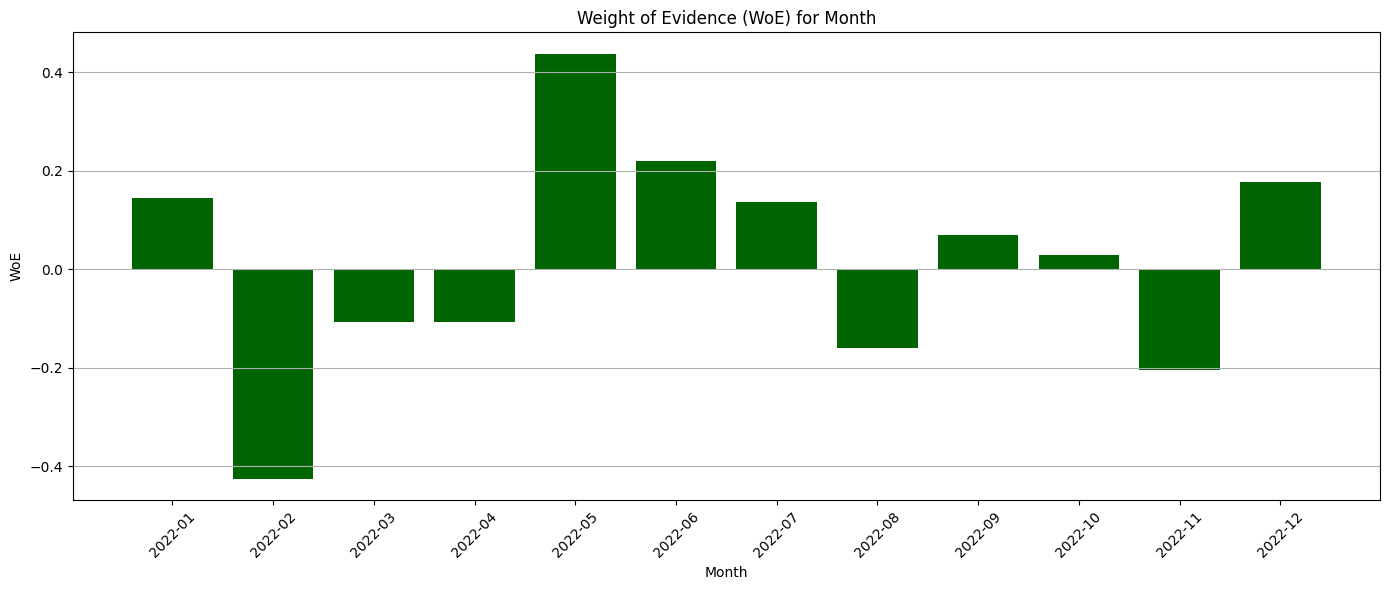

In [18]:
# Encode the transactionType using WoE and generate a plot 
df_train, df_val = woe_plot_encode(df_train, "Month", "fraud", "darkgreen", df_val)

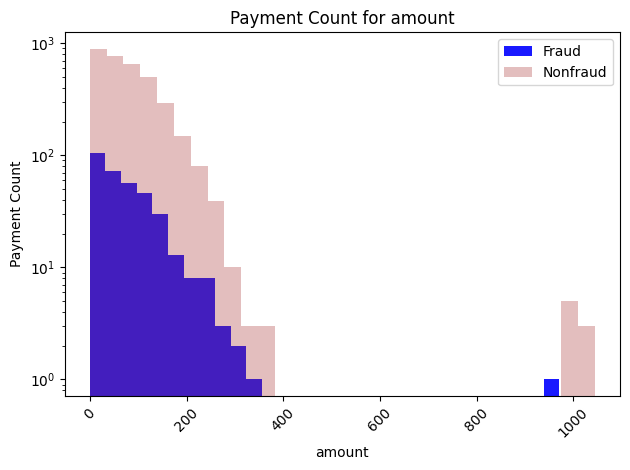

In [19]:
# Plot the histogram for amount
histogram_fraud(df_train, "amount", "fraud", 30)

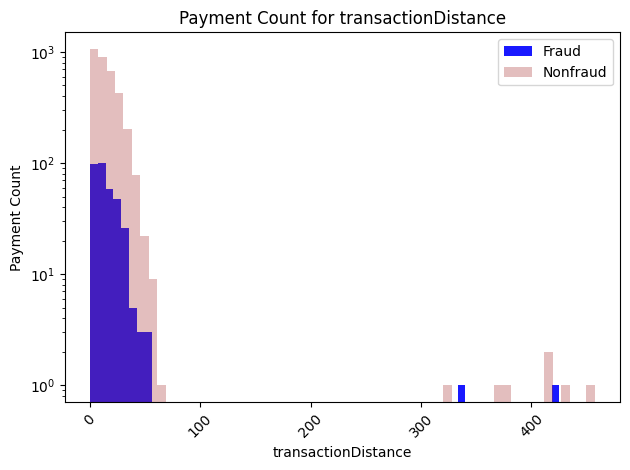

In [20]:
# Plot the histogram for amount
histogram_fraud(df_train, "transactionDistance", "fraud", 60)

## 3) Feature Engineering

##### This section defines the set of features that will be passed into the fraud detection model

-  Some initial feature engineering was done earlier to create the senderID and receiverID counts.
-  Two more features related to time were created: Weekend and Holiday.
-  Both "transactionType" and "Month" were encoded previously.
-  Data is now split into X,y for both train and test.

In [21]:
df_train = create_dow_features(df_train, "transactionDate")
df_val = create_dow_features(df_val, "transactionDate")

In [22]:
df_train.columns

Index(['senderID', 'amount', 'transactionDate', 'hasMemo', 'receiverID',
       'senderAcctTenure', 'receiverAcctTenure', 'transactionDistance',
       'fraud', 'senderID_2d_count', 'senderID_7d_count', 'senderID_30d_count',
       'senderID_90d_count', 'receiverID_2d_count', 'receiverID_7d_count',
       'receiverID_30d_count', 'receiverID_90d_count',
       'senderID_2d_fraudcount', 'senderID_7d_fraudcount',
       'senderID_30d_fraudcount', 'senderID_90d_fraudcount',
       'receiverID_2d_fraudcount', 'receiverID_7d_fraudcount',
       'receiverID_30d_fraudcount', 'receiverID_90d_fraudcount',
       'transactionType_WoE', 'Month_WoE', 'Weekend', 'Holiday'],
      dtype='object')

In [23]:
# Split the data into X,y
columns_to_keep = ["amount", "hasMemo", "senderAcctTenure", "receiverAcctTenure", "transactionDistance", "Weekend", "Holiday", 
                       "Month_WoE", "transactionType_WoE"] + [col for col in df.columns if col.endswith("count")]
X_train = df_train[columns_to_keep]
X_val = df_val[columns_to_keep]
y_train = df_train["fraud"]
y_val = df_val["fraud"]

## 4) Modeling

##### This section looks at the performance of some initial machine learning models

-  The 3 numeric features with missing values will be imputed with the median value
-  A standard scaler is used to standardzie the data to mean 0 and st dev 1. Useful for LASSO logsitic we will try.
-  The first pass has weaker model performance without tuning, feature selection, and oversampling
-  The third pass with tuning and feature selection but no oversampling performs the best
-  Feature importance plot confirms the value of the lookback window features for senderID and receiverID

In [24]:
# from sklearn.impute import SimpleImputer
# from sklearn.linear_model import LogisticRegression
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import StandardScaler
# from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score, precision_recall_curve
# from sklearn.model_selection import GridSearchCV
# from xgboost import XGBClassifier

In [25]:
from training import impute_scale_train, impute_scale_tune_train
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

scikit-learn not found. Installing...
scikit-learn installed successfully.
xgboost is already installed.


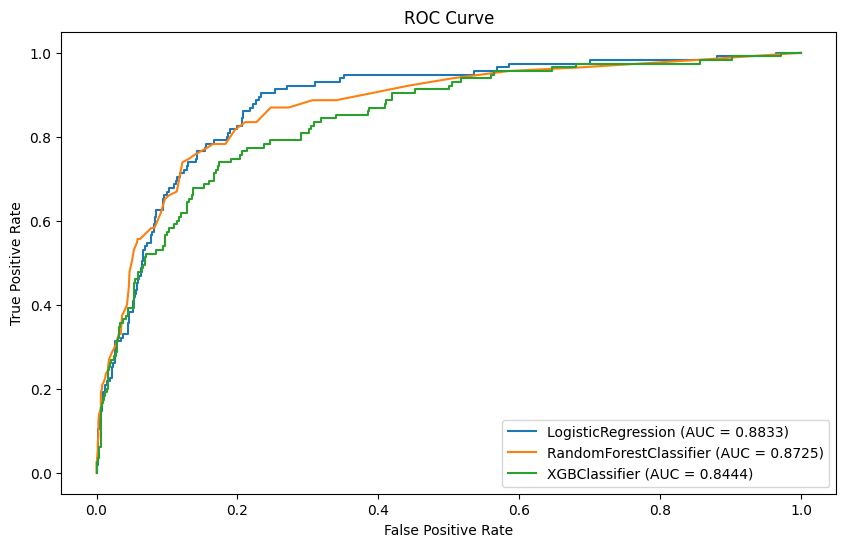

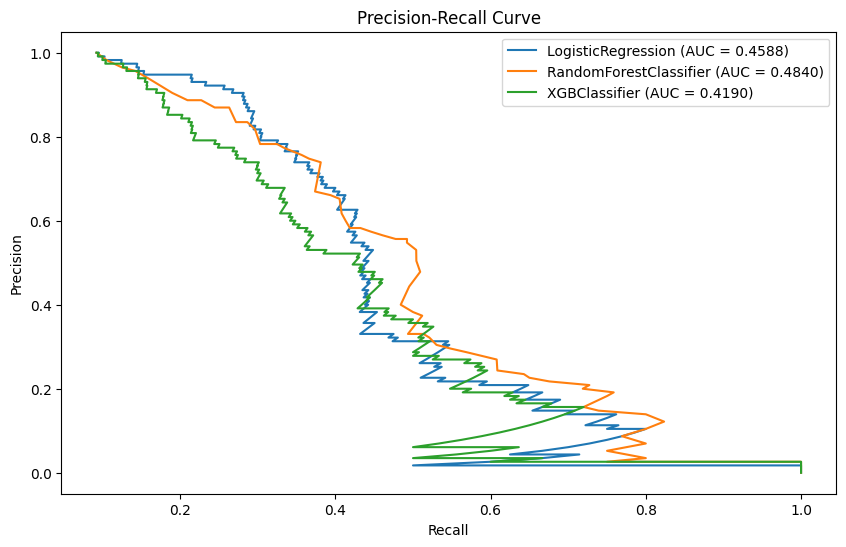

In [26]:
# Define models
models = [LogisticRegression(), RandomForestClassifier(), XGBClassifier()]

# Evaluate each model
fig_roc, ax_roc = plt.subplots(figsize = (10, 6))
fig_pr, ax_pr = plt.subplots(figsize = (10, 6))
for model in models:
    impute_scale_train(X_train, X_val, y_train, y_val, model, ax_roc, ax_pr)

ModuleNotFoundError: No module named '_posixsubprocess'

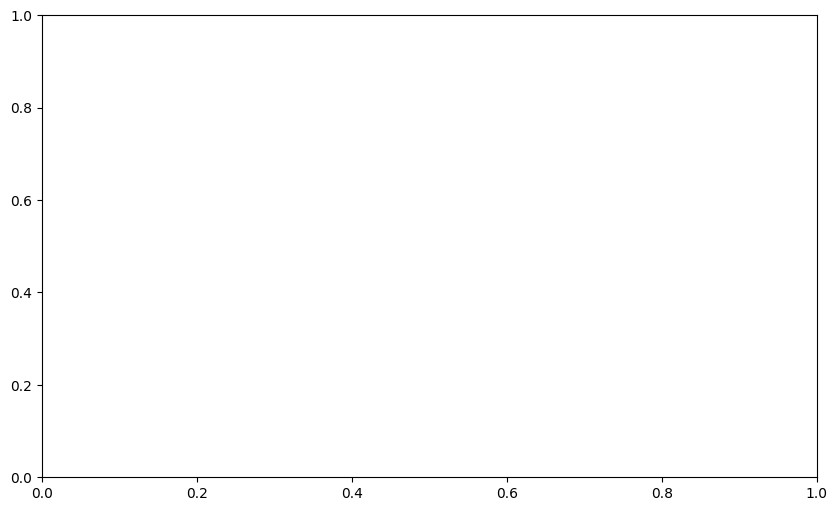

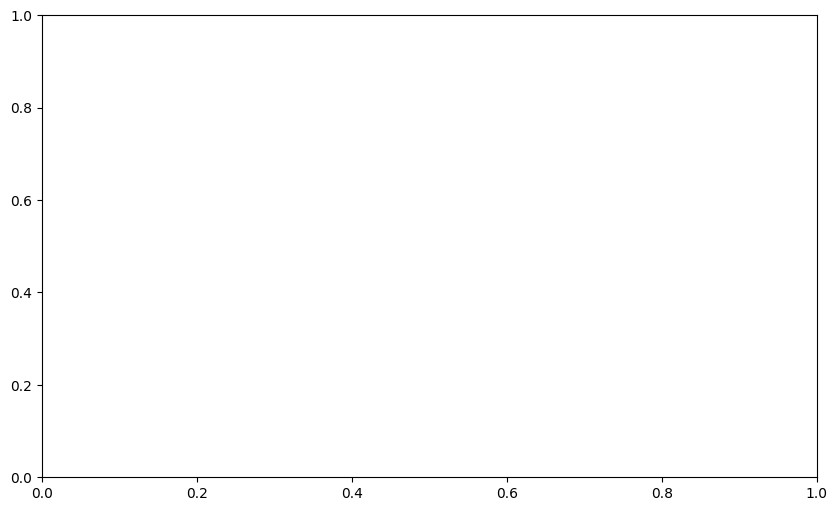

In [27]:
'''
The initial results are suprising, as they indicate the LogisticRegression model is the highest performer and XGBoost is the lowest.
One possible reason for this is the tree-based models are overfitting on a small dataset. I will try hyperparameter tuning:
'''

# Define models
models = [LogisticRegression(random_state = 1234), RandomForestClassifier(random_state = 1234), XGBClassifier(random_state = 1234)]
# Define parameter grids
param_grids = [{
    "classifier__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    "classifier__penalty": ["l1"],
    "classifier__solver": ["liblinear", "saga"]
},
{
    "classifier__max_depth": [4, 5, 6, 7],
    "classifier__n_estimators": [10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 5, 10],
    "classifier__max_features": ["sqrt", "log2"]
},
{
    "classifier__max_depth": [4, 5, 6, 7],
    "classifier__n_estimators": [10, 20, 30],
    "classifier__gamma": [0.5, 1, 2, 4, 6],
    "classifier__min_child_weight": [1, 5, 10],
    "classifier__eta": [0.01, 0.1, 0.2]
}]

# Evaluate each model
fig_roc, ax_roc = plt.subplots(figsize = (10, 6))
fig_pr, ax_pr = plt.subplots(figsize = (10, 6))
list_of_tuned_models = list()
for model, param_grid in zip(models, param_grids):
    list_of_tuned_models.append(impute_scale_tune_train(X_train, X_val, y_train, y_val, 
                                                        model, ax_roc, ax_pr, param_grid))

In [ ]:
# Hyperparameter tuning has improved performance. Now try feature selection

from sklearn.feature_selection import SelectKBest

def model_performance_tuning_fs(model, X_train, X_test, y_train, y_test, param_grid, ax_roc, ax_pr):
    
    imputer = SimpleImputer(strategy = "median")
    scaler = StandardScaler()
    kbest = SelectKBest(k = 15)
    pipe = Pipeline(steps = [("impute", imputer), 
                             ("scale", scaler), 
                             ("fs", kbest),
                             ("classifier", model)])

    grid = GridSearchCV(pipe, param_grid, cv = 5, n_jobs = -1, scoring = "average_precision", refit = True)   
    grid.fit(X_train, y_train)
    model_scores = grid.predict_proba(X_test)[:,1]
    # Print the best parameters
    print("Best parameters:", grid.best_params_)
    # Print the best score
    print("Best score:", grid.best_score_)

    # Plot ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, model_scores)
    auroc = roc_auc_score(y_test, model_scores)
    ax_roc.plot(fpr, tpr, label = f"{model.__class__.__name__} (AUC = {auroc:.4f})")
    ax_roc.set_xlabel("False Positive Rate")
    ax_roc.set_ylabel("True Positive Rate")
    ax_roc.set_title("ROC Curve")
    ax_roc.legend()

    # Plot PR curve
    fpr, tpr, thresholds = precision_recall_curve(y_test, model_scores)
    auprc = average_precision_score(y_test, model_scores)
    ax_pr.plot(fpr, tpr, label = f"{model.__class__.__name__} (AUC = {auprc:.4f})")
    ax_pr.set_xlabel("Recall")
    ax_pr.set_ylabel("Precision")
    ax_pr.set_title("Precision-Recall Curve")
    ax_pr.legend()

    return grid.best_estimator_

In [ ]:
# Evaluate each model
fig_roc, ax_roc = plt.subplots(figsize = (10, 6))
fig_pr, ax_pr = plt.subplots(figsize = (10, 6))
list_of_fs_models = list()
for model, param_grid in zip(models, param_grids):
    list_of_fs_models.append(model_performance_tuning_fs(model, X_train, X_test, y_train, y_test, param_grid, ax_roc, ax_pr))

In [ ]:
# Fianlly try SMOTE to oversample the minortiy class

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

def model_performance_tuning_smote(model, X_train, X_test, y_train, y_test, param_grid, ax_roc, ax_pr):
    
    imputer = SimpleImputer(strategy = "median")
    scaler = StandardScaler()
    kbest = SelectKBest(k = 15)
    smote = SMOTE(sampling_strategy = 0.5, random_state = 1234)
    pipe = Pipeline(steps = [("impute", imputer), 
                             ("scale", scaler),
                             ("fs", kbest),
                             ("smote", smote),
                             ("classifier", model)])

    grid = GridSearchCV(pipe, param_grid, cv = 5, n_jobs = -1, scoring = "average_precision", refit = True)   
    grid.fit(X_train, y_train)
    model_scores = grid.predict_proba(X_test)[:,1]
    # Print the best parameters
    print("Best parameters:", grid.best_params_)
    # Print the best score
    print("Best score:", grid.best_score_)

    # Plot ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, model_scores)
    auroc = roc_auc_score(y_test, model_scores)
    ax_roc.plot(fpr, tpr, label = f"{model.__class__.__name__} (AUC = {auroc:.4f})")
    ax_roc.set_xlabel("False Positive Rate")
    ax_roc.set_ylabel("True Positive Rate")
    ax_roc.set_title("ROC Curve")
    ax_roc.legend()

    # Plot PR curve
    fpr, tpr, thresholds = precision_recall_curve(y_test, model_scores)
    auprc = average_precision_score(y_test, model_scores)
    ax_pr.plot(fpr, tpr, label = f"{model.__class__.__name__} (AUC = {auprc:.4f})")
    ax_pr.set_xlabel("Recall")
    ax_pr.set_ylabel("Precision")
    ax_pr.set_title("Precision-Recall Curve")
    ax_pr.legend()

    return grid.best_estimator_

In [ ]:
# Evaluate each model
fig_roc, ax_roc = plt.subplots(figsize = (10, 6))
fig_pr, ax_pr = plt.subplots(figsize = (10, 6))
list_of_smote_models = list()
for model, param_grid in zip(models, param_grids):
    list_of_smote_models.append(model_performance_tuning_smote(model, X_train, X_test, y_train, y_test, param_grid, ax_roc, ax_pr))

In [ ]:
'''
The model with the largest AUPRC on the holdout sample was XGBoost. XGBoost performed the best when tuned with feature selection, but without SMOTE.
I will move forward with XGBoost under the assumption the objective is to maximimize model performance in spite of the increased requirements 
from engineering. If instead the objective was to balance simplicity of deployment with performance, I would stick with a Logistic Regression
model. 
'''

# Look at feature importance
feature_names = X_test.iloc[:,list_of_fs_models[2].named_steps["fs"].get_support(indices=True)].columns
feature_importances = list_of_fs_models[2].named_steps["classifier"].feature_importances_
df_fi = pd.DataFrame({"Feature": feature_names, "Importance": feature_importances}).sort_values(by = "Importance")
df_fi = df_fi[df_fi["Importance"] != 0]

plt.figure(figsize = (10, 6))
plt.barh(df_fi["Feature"], df_fi["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance Plot")
plt.show()

In [ ]:
# Final step is to pick an ideal threshold for the model.

# Get the required f1 and sorted data
output = list_of_fs_models[2].predict_proba(X_test)[:,1]
ind = X_test.index
dft = pd.DataFrame({"Prediction": output, "ID": ind, "fraud": y_test}).sort_values(by = "Prediction", ascending = False)
df_thresh = dft.groupby("Prediction").agg({"ID": ["count"], "fraud": ["sum"]}).sort_values("Prediction", ascending = False).droplevel(0, axis = 1)
df_thresh["recall"] = df_thresh["sum"].cumsum() / df_thresh["sum"].sum()
df_thresh["precision"] = df_thresh["sum"].cumsum() / df_thresh["count"].cumsum()
df_thresh["f1"] = (2 * df_thresh["recall"] * df_thresh["precision"]) / (df_thresh["recall"] + df_thresh["precision"])
df_thresh["perc_txns"] = 100 * df_thresh["count"].cumsum() / dft.shape[0]
df_thresh = df_thresh.reset_index()
max_f1 = round(max(df_thresh["f1"]), 3)
max_perc_txns = round(df_thresh["perc_txns"][df_thresh["f1"].argmax()], 3)

#Plot the curve

plt.figure(figsize = (10, 6))
plt.plot(df_thresh["perc_txns"], df_thresh["f1"], color = "darkgreen")
plt.vlines(x = max_perc_txns, ymin = 0, ymax = max_f1, color = "black", ls = "--")
plt.plot(max_perc_txns, max_f1, marker = "o", color = "black")
plt.text(max_perc_txns, max_f1, "({}, {})".format(max_perc_txns, max_f1))
plt.xlabel("% Transactions")
plt.ylabel("f1 Score")
plt.title("f1 Score by % Txns")
plt.show()